# Shazam (Part 2)

A Running exercise to replicate the Shazam algorithm.

## Goals

- More practice with pandas `DataFrames`
- Building intuition for distances
- Experimenting with evaluation strategies

## Setup

Run the following 2 cells to import all necessary files, libraries and helpers for this exercise.

In [1]:
!mkdir -p data/audio
!wget -q https://github.com/PSAM-5020-2026F-A/5020-utils/raw/refs/heads/main/datasets/audio/hood-internet.tar.gz
!tar -xzf ./hood-internet.tar.gz -C ./data/audio/ && rm -rf hood-internet.tar.gz*

In [2]:
import librosa
import matplotlib.pyplot as plt
import pandas as pd
import random

from IPython.display import Audio
from os import listdir

### ❗️❗️ WARNING ❗️❗️

The songs we'll be using are from mixtapes by [The Hood Internet](https://www.thehoodinternet.com/). They were part of a wave of _mashup_ producers in the early $2\text{,}000\text{s}$ that mixed _classic_ american indie, pop and rap music from other time periods.

We're using their mixtapes here mostly because: they're available freely on the internet, they encompass a good variety of songs and styles, and there are a good number of songs; not too few nor too many.

The lyrics mostly come from the rap songs being sampled and contain references to all the things that rap artists were rapping about in the $90\text{s}$ and $00\text{s}$ (sex, drugs, guns, money...).

We definitely don't have to listen to the songs to complete the exercise.

We can consider alternative datasets for this exercise. Feel free to adapt the exercise to use files from different albums, just indicate that here in the notebook.

## Shazam !

Ok. Let's continue our journey of replicating the Shazam algorithm.

As a review: it's the same type of classification task we've been looking at, but instead of classifying a piece of audio into one of $3$ classes, the algorithm has to pick which of the millions of songs the piece of audio most likely came from.

Instead of manually extracting features, we need something a little more systematic.

Mel-Frequency Cepstral Coefficients (MFCC) is a techninque for automatically extracting meaningful numeric information from audio, independent of the type of audio.

We'll continue to use the librosa library to help us extract MFCCs from audio.

### Review: MFCCs

In [3]:
# First, let's grab all audio file names from our album directory

TRACKS_DIR = "./data/audio/hood-internet/mixtape04"
fnames = sorted([f for f in listdir(TRACKS_DIR) if f.endswith("mp3")])

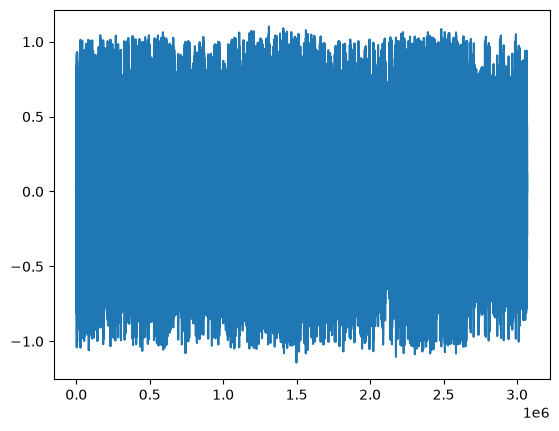

In [4]:
# opening up a random song (index 4)
y,sr = librosa.load(f"{TRACKS_DIR}/{fnames[4]}")

plt.plot(y)
plt.show()

display(Audio(y, rate=sr))

In [5]:
# Extracting the mfccs for track at index 4.
# We use mean(axis=1) to get a single value for each frequency channel, independent of time.

mfccs = librosa.feature.mfcc(y=y, n_mfcc=10).mean(axis=1)

print(mfccs.shape)
display(mfccs)

(10,)


array([-0.74746543, 92.35462   ,  0.19578417, 16.9823    ,  6.9186482 ,
       15.270939  , -1.3177572 ,  7.6062403 , -1.5181429 ,  5.7080293 ],
      dtype=float32)

### Review: Extract MFCC features from all songs

It takes about $20$ seconds to extract features for all songs.

In [6]:
# Helper function
def get_features(y, n_mfcc=20):
  mfeats = {}
  mfccs = librosa.feature.mfcc(y=y, n_mfcc=n_mfcc).mean(axis=1)
  for idx,fcc in enumerate(mfccs):
    mfeats[f"mfcc{idx}"] = float(fcc)
  return mfeats

In [7]:
# This cell takes about 20-30 seconds

track_feats = []

for f in fnames:
  fpath = f"{TRACKS_DIR}/{f}"
  y, sr = librosa.load(fpath)
  track_feats.append(get_features(y=y))

tracks_df = pd.DataFrame.from_records(track_feats)
tracks_df

,mfcc0,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19
0,-82.586060,79.532730,15.281947,29.399260,6.727077,11.497275,-0.073768,11.575369,-3.011040,10.090432,-0.660233,3.245026,1.092702,1.200370,-1.564980,3.827295,-3.170717,1.272093,-2.106808,1.561773
1,-36.498466,68.565880,1.131177,17.951372,5.481598,9.588413,-5.838254,0.816502,-4.664019,-0.872571,-5.979408,3.180954,-4.455261,0.461847,-0.487985,1.974657,-6.495473,-0.648695,-4.788703,-2.601770
2,-14.431624,91.889542,-17.692987,20.666237,2.245853,13.001684,-1.321214,9.948376,-0.615950,11.860087,1.530263,6.526819,-1.141762,4.144239,-2.058718,3.202840,-1.356414,2.854834,0.653201,3.837844
3,-62.079441,79.199989,5.043945,10.326107,14.655840,3.606573,-6.818017,7.708108,-0.689195,3.924184,-2.623504,3.656586,-4.205101,-3.083404,-3.361222,-0.709391,-5.950740,3.015170,-2.148083,-1.850845
4,-0.747465,92.354622,0.195784,16.982300,6.918648,15.270939,-1.317757,7.606240,-1.518143,5.708029,0.671459,4.795196,-1.870469,1.411490,-0.311129,1.396400,-1.223180,3.015442,-4.852983,-0.309421
5,-35.664974,73.733498,4.196826,16.117207,0.898156,6.703715,-1.960575,4.447550,-1.939743,5.270139,-5.431313,2.591826,-2.935765,3.732988,-3.821752,3.176196,-2.622354,4.038076,-0.720880,0.954932
6,-34.479401,71.243324,11.187264,11.472790,4.763395,8.362548,-0.957873,5.603895,-2.738507,0.952181,-2.665535,2.161973,0.253431,2.913933,-0.699769,3.659111,-4.761374,1.822548,-2.936781,-0.380950
7,-28.663395,83.778824,11.784966,25.143528,10.610123,13.076379,1.660900,8.122109,1.959449,7.608665,3.474735,7.115009,4.217964,3.992178,-0.416719,5.486871,-2.944684,4.116807,-0.045946,3.995268
8,-25.007885,70.711952,6.459869,24.236881,9.859155,9.727757,3.846369,7.556618,-2.184863,6.845351,-1.877875,5.675496,-0.284641,2.302318,-2.303686,1.616386,-2.673212,3.514842,-2.295441,0.128937
9,-15.857485,87.658066,-22.861092,33.988007,-3.307864,11.846355,3.919635,6.607801,0.544680,8.447746,0.931829,6.537024,-1.623442,5.684522,-1.682151,4.318871,-2.179642,1.036895,-1.852589,2.837394


### Review: Shazam

This is what's behind the [Shazam algorithm](https://www.youtube.com/watch?v=b6xeOLjeKs0): a large database of songs, where each song is described with only a few features so they can be organized, searched, queried and compared very very quickly.

Another [video](https://www.youtube.com/watch?v=kMNSAhsyiDg) reference.

Let's implement something like this.

We're focusing on a single album, with about $30$ songs, but the same strategy (with minor modifications) will work for datasets of many more songs.

Here's the outline of what we are doing to do:

1. Extract MFCC features from all songs in our database (single album) ✅
2. Create a dataset of song features ✅
3. Given an input sound clip: extract its MFCC features
4. Find closest song in database by feature distance

### Multi-dimensional distance

We stopped with this challenge last time.

The next step is to create a function that, given a set of mfcc features, finds the song in our dataset with the most similar features.

This is similar to one of the exercises in Homework02, where we found the closest cities to a given city; and similar to the MoMA exercise, where we found the closest apartment to a location.

The difference is that in those cases our distance was calculated using $2$ features (latitude and longitude), but now our distances will be calculated using $20$ (or so) features.

The math is the same. Since the number of features is not fixed and is greater than $5$, we should use a loop, possibly with [`row.index`](https://pandas.pydata.org/docs/reference/api/pandas.Series.index.html) (similar to `df.columns`) or `zip()`...

In [8]:
# TODO: implement a function that returns distances between 2 mfcc feature lists
def mfcc_dist(mfccA, mfccB):
  sum_of_squares = 0

  # TODO: iterate over pairs of features
  # calculate the sum of the square of their differences
  # return the square root of that sum
  for a, b in zip(mfccA, mfccB):
    sum_of_squares += (a - b) ** 2
  return sum_of_squares ** 0.5

In [9]:
# quick check
song0 = list(tracks_df.iloc[0])
song1 = list(tracks_df.iloc[1])

print(mfcc_dist(song0, song0))   
print(mfcc_dist(song0, song1))  

0.0
54.3711323513913


### 3. Given an input sound clip: extract its MFCC features

In [10]:
# Let's open the track at index 4 and get 5 seconds of audio from the center of the song

# Track at index 4
fpath = f"{TRACKS_DIR}/{fnames[4]}"
y_in, sr_in = librosa.load(fpath)

# get 5 seconds from middle of song
midx = int(len(y_in) // 2)
half_win = int(2.5 * sr_in)
samples_5sec = y_in[midx - half_win : midx + half_win]

feat_in = get_features(samples_5sec)

# And create DataFrame with MFCC features for the 5-second clip
# A Series is like a 1-row DataFrame, which is what we have for the MFCCs of a single song clip

in_df = pd.Series(feat_in)
in_df

mfcc0      1.716580
mfcc1     87.468460
mfcc2      6.318439
mfcc3     12.315375
mfcc4     12.069894
mfcc5     18.375807
mfcc6     -2.391828
mfcc7     10.091451
mfcc8      1.148137
mfcc9      6.964205
mfcc10     1.571906
mfcc11     2.877960
mfcc12    -1.236404
mfcc13     3.085088
mfcc14     2.284000
mfcc15     1.523134
mfcc16    -1.931718
mfcc17     3.127093
mfcc18    -3.184851
mfcc19     1.231899
dtype: float64

In [11]:
print(len(samples_5sec))  
print(len(in_df))   

110250
20


### 4. Find closest song in database by feature distance

We have MFCCs for all songs and MFCCs for the wanted clip.

We'll go through the dataset and create a new feature called `distance` that holds the MFCC distance between all songs and the target.

We can loop through a `DataFrame` using [`df.iterrows()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iterrows.html), or we can apply a function to all rows using [`df.apply()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html).

In [12]:
# TODO: loop through rows or apply a function to all rows
distances = []
for idx, row in tracks_df.iterrows():
  distances.append(mfcc_dist(list(row), list(in_df)))

# TODO: add results to song DataFrame as a column called "distance"
tracks_df["distance"] = distances

# peek at the closest songs
tracks_df.sort_values("distance").head()

,mfcc0,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,...,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19,distance
4,-0.747465,92.354622,0.195784,16.982300,6.918648,15.270939,-1.317757,7.606240,-1.518143,5.708029,...,4.795196,-1.870469,1.411490,-0.311129,1.396400,-1.223180,3.015442,-4.852983,-0.309421,12.709004
20,-8.647201,95.706314,1.616024,20.072241,5.667694,8.149070,2.181114,7.932672,0.133707,5.549460,...,3.163464,-2.875108,2.210821,-2.468525,1.058773,-5.151648,1.088687,-4.176623,-0.393343,21.830957
16,-13.566113,81.105560,-2.128357,20.265041,2.747745,12.105445,0.518556,0.980654,-4.380493,2.043630,...,1.054461,-1.805910,2.679757,-0.342421,4.996310,-3.088338,3.063874,-2.490129,1.395397,26.574429
13,4.097200,78.657806,-2.644476,19.867725,4.517694,4.408960,-5.419432,2.935398,-1.770762,1.615597,...,-2.558482,-3.248969,0.266363,-3.033791,-0.185096,-3.860604,-0.909747,-4.364478,1.348641,26.984851
32,-15.195163,94.775757,5.371995,14.047431,10.663271,4.051098,-12.057905,7.319236,-4.578975,2.309551,...,6.109654,-5.640357,-1.049908,-2.678415,3.064675,-3.818236,0.198233,-3.256135,-1.129988,29.421308


In [14]:
song_name = tracks_df["distance"].idxmin()
print(song_name, fnames[song_name])

4 05 Lil Wayne (feat. Babyface) x Royksopp - Comfortable Up Here.mp3


### Almost there

We have the distance values in a column, so we just have to find the index of the row with the smallest distance.

There are many ways of doing this, but a general strategy that can be easily extended later when evaluating our algorithm, is to use [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html), and [`index`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.index.html).

Using [`idxmin()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.idxmin.html) is easier, but it only gives us the closest row index.

When the prediction is wrong, using the [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) strategy will also tell us how far the correct index was from being predicted.

In [15]:
# TODO: find index of row with smallest "distance" value
closest_idx = tracks_df["distance"].idxmin()
print(closest_idx, fnames[closest_idx])

# TODO: sort DataFrame by distance values
sorted_df = tracks_df.sort_values("distance")

# TODO: look at first index
print(sorted_df.index[0])
print(list(sorted_df.index[:5]))

4 05 Lil Wayne (feat. Babyface) x Royksopp - Comfortable Up Here.mp3
4
[4, 20, 16, 13, 32]


In [ ]:
# check-- if prints 0 then it is close/
true_idx = 4
rank = list(sorted_df.index).index(true_idx)
print(rank)

0


### 5. Evaluate

We should calculate how often our Shazam algorithm is right.

This can be done by implementing the following set of steps:
1. Initialize a counter to keep track of number of correct predictions
2. For $N$ predictions (where $N$ can be $10$, $100$, $1000$, etc ...)
3. Pick a random track from the album
4. Pick a random $5$ second clip from the random track
5. Extract features, compare to features in `tracks_df` and predict which track it is
6. If prediction correct, increment correct predictions counter

Alternatively, instead of only incrementing the correct predictions counter when the correct track is the very first on the list of possible tracks, we can increment the counter if the correct track is in the $\text{top-}3$ predictions. This is the $\text{top-}3$ accuracy of our classifier, which, instead of being a binary measurement of right/wrong, also gives us a bit of credit for being "close".

In [17]:
# TODO: write a function called random5() that
#receives an audio file path, extracts MFCC features from 
# a random 5-second portion of the audio and returns a Series with the features
  # TODO: possible strategy:
  #       load song
  #       convert 5 seconds to number of samples
  #       random.randrange() can help pick the starting sample between 0 and 5 seconds from the end of the song.
  #       use slicing to extract the samples corresponding to the selected 5-second range
  #       run get_features() and convert to Series before returning

def random5(fpath):
  # load the whole song just to use 5 seconds of it. a bit wasteful?
  y, sr = librosa.load(fpath)

  # 5 seconds -> number of samples.
  n_samples = int(5 * sr)

  # latest possible start is 5 seconds before the end, so the clip never runs off the song
  # (randrange excludes the upper bound)
  start = random.randrange(0, len(y) - n_samples)

  # is a random clip a fair test? it could land on a quiet intro or a long outro...
  clip = y[start : start + n_samples]

  # 20 numbers to describe 5 seconds of a mashup
  feats = get_features(clip)

  # a Series so it matches what we did for in_df earlier
  return pd.Series(feats)

In [18]:
# test
test_feats = random5(f"{TRACKS_DIR}/{fnames[4]}")
print(len(test_feats))   # 20

20


We'll also need a function for comparing the `DataFrame` of songs and the `DataFrame` of the input clip.

We just have to wrap the distance calculation and the search for the smallest distance from above in a function.


Again, we should use [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) here and return a list of the predictions. This way when the first prediction is wrong we can see how wrong it was by finding the correct answer in the list of predictions.

In [ ]:
# TODO: implement comparison function
# TODO: repeat code from above to find index of row with the shortest distance
def compare_predict(tracks_df, in_df):
  # use only the MFCC columns
  mfcc_cols = [c for c in tracks_df.columns if c.startswith("mfcc")]
  clip_feats = list(in_df[mfcc_cols])
    # distance from the clip to every song
  distances = []
  for idx, row in tracks_df[mfcc_cols].iterrows():
    distances.append(mfcc_dist(list(row), clip_feats))

  # work on a copy so we have a static version and one that we 
  # can re-write without it changing the original
  scored_df = tracks_df.copy()
  scored_df["distance"] = distances

  # closest song first--> the index labels are the song numbers
  return list(scored_df.sort_values("distance").index)

In [20]:
# test with track 4
preds = compare_predict(tracks_df, in_df)
print(preds[:5])             
print(preds[0] == 4)        
print(4 in preds[:3])       

[4, 20, 16, 13, 32]
True
True


Now we use the above defined functions to run some tests.

With the `random5()` and `compare_predict()` functions defined above we should be able to just run the following cell to evaluate our classifier.

We want to eventually run $200$ to $500$ tests, but we can start with $10$ just to make sure the code works.

In [21]:
num_tests = 10
num_correct = 0
num_correct_top3 = 0

for _ in range(num_tests):
  # pick a random song
  rtrack_idx = random.randrange(0, len(fnames))
  rtrack_name = fnames[rtrack_idx]

  # extract features from random 5-second clip of song
  in_df = random5(f"{TRACKS_DIR}/{rtrack_name}")

  # compare, and keep track of correct predictions
  predictions = compare_predict(tracks_df, in_df)

  if rtrack_idx == predictions[0]:
    num_correct += 1
  if rtrack_idx in predictions[:3]:
    num_correct_top3 += 1

# print accuracy (number of correct predictions divided by total tests)
print(f"top 1: {round(num_correct / num_tests * 100, 2)}%")
print(f"top 3: {round(num_correct_top3 / num_tests * 100, 2)}%")

top 1: 70.0%
top 3: 80.0%


### Improve the Algorithm ?

Not bad.

(Re)Watch the Shazam video [here](https://www.youtube.com/watch?v=b6xeOLjeKs0). What's the one big difference between their algorithm and ours ?

(You don't have to improve the code. Just think about what could be some potential next steps.)

isa thoughts I thought about admist this...
* Do longer clips (10 or 15 seconds) match better than 5 seconds? I would assume so as there would be more to compare/reference to
* random5 reloads a whole song for every test. I think it would benefit for a way to load each song once and so that they do not repeat, and maybe have a catalog of guesses/non-guessed songs
* A clip that lands on silence or a very quiet part probably fails or would have incorrect guesses
